# ANN(Multi-Layer Perceptron)

[Contents]
1. Over-fitting vs Under-fitting  
2. Nodes수 에 따른 성과비교  
3. Layer Depth에 따른 성과비교  
4. 일반화 성능비교 (EarlyStopping+Dropout)

[Data]  
Heart Disease Data set (Classification)  
https://archive.ics.uci.edu/dataset/45/heart+disease
shape : 303*13
  
[Task]
1. 아래 2개의 데이터 중 택일하여  
 - 활용데이터1 : Adult(Census Income)(2)
 - https://archive.ics.uci.edu/dataset/2/adult
 - 활용데이터2 : Bank Marketing(222)
 - https://archive.ics.uci.edu/dataset/222/bank+marketing


[Note]


In [2]:
#  UCI Machine Learning Data Load Library
!pip install ucimlrepo

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from ucimlrepo import fetch_ucirepo
import warnings
warnings.filterwarnings('ignore')


In [4]:
# 1. Data Loading
print("=== Data Loading ===")
heart_disease = fetch_ucirepo(id=45)
X = heart_disease.data.features
y = heart_disease.data.targets

df = pd.DataFrame(X, columns=heart_disease.feature_names)
df['target'] = y

print(f"Data Shape: {df.shape}")
print(f"Info: {df.info()}")
print(f"Samples: {df.head(5)}")

=== Data Loading ===
Data Shape: (303, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB
Info: None
Samples:    age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   63    1   1       145   233    1        2      150      0      2.3     

In [6]:
# 2. EDA
print("\n결측치 확인:")
print(df.isnull().sum())

print("\n타겟 변수 분포:")
print(f"Target Class Name: {heart_disease.target_names}")
target_counts = df['target'].value_counts()
print(target_counts)
print(f"비율: {target_counts / len(df) * 100}")



결측치 확인:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

타겟 변수 분포:
Target Class Name: None
target
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64
비율: target
0    54.125413
1    18.151815
2    11.881188
3    11.551155
4     4.290429
Name: count, dtype: float64


In [7]:
# 3. Data Preprocessing

# Handle missing values
X = X.fillna(X.mean())
y = (y > 0).astype(int).values.ravel()  # Convert to binary classification

# Train/Validation/Test split
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp)

# Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

n_features = X_train_scaled.shape[1]
print(f"Number of features after preprocessing: {n_features}")

Number of features after preprocessing: 13


In [8]:
# 4. Model Functions : MLP생성모듈
def create_underfitting_model(input_dim):
    """Underfitting model - too simple"""
    model = keras.Sequential([
        layers.Dense(2, activation='relu', input_shape=(input_dim,)),
        layers.Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

def create_balanced_model(input_dim, hidden_units):
    """Well-balanced model"""
    model = keras.Sequential([
        layers.Dense(hidden_units, activation='relu', input_shape=(input_dim,)),
        layers.Dropout(0.3),
        layers.Dense(hidden_units//2, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

def create_overfitting_model(input_dim):
    """Overfitting model - too complex"""
    model = keras.Sequential([
        layers.Dense(256, activation='relu', input_shape=(input_dim,)),
        layers.Dense(128, activation='relu'),
        layers.Dense(64, activation='relu'),
        layers.Dense(32, activation='relu'),
        layers.Dense(16, activation='relu'),
        layers.Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

def create_deep_model(input_dim, hidden_units, n_layers):
    """Deep model for depth experiments"""
    model = keras.Sequential()
    model.add(layers.Dense(hidden_units, activation='relu', input_shape=(input_dim,)))

    for _ in range(n_layers - 1):
        model.add(layers.Dense(hidden_units, activation='relu'))
        model.add(layers.Dropout(0.2))

    model.add(layers.Dense(1, activation='sigmoid'))
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

# Model Training Function
def train_model(model, model_name, epochs=100):
    history = model.fit(
        X_train_scaled, y_train,
        validation_data=(X_val_scaled, y_val),
        epochs=epochs,
        batch_size=32,
        verbose=0
    )

    # Test performance evaluation
    test_loss, test_accuracy = model.evaluate(X_test_scaled, y_test, verbose=0)
    print(f"{model_name} - Test Accuracy: {test_accuracy:.4f}")

    return history, test_accuracy


In [9]:
# 5. 실험1: Underfitting vs Overfitting
print("\n=== Experiment 1: Underfitting vs Overfitting ===")

models_comparison = {}

# Underfitting model
under_model = create_underfitting_model(n_features)
under_history, under_acc = train_model(under_model, "Underfitting Model")
models_comparison['Underfitting'] = {'history': under_history, 'accuracy': under_acc}

# Balanced model (n nodes)
balanced_model = create_balanced_model(n_features, n_features)
balanced_history, balanced_acc = train_model(balanced_model, f"Balanced Model ({n_features} nodes)")
models_comparison['Balanced'] = {'history': balanced_history, 'accuracy': balanced_acc}

# Overfitting model
over_model = create_overfitting_model(n_features)
over_history, over_acc = train_model(over_model, "Overfitting Model")
models_comparison['Overfitting'] = {'history': over_history, 'accuracy': over_acc}



=== Experiment 1: Underfitting vs Overfitting ===
Underfitting Model - Test Accuracy: 0.8361
Balanced Model (13 nodes) - Test Accuracy: 0.8525
Overfitting Model - Test Accuracy: 0.8033


In [10]:
# 6. 실험 2: Hidden Layer Node수에 따른 비교 (n vs 2n)
print("\n=== Experiment 2: Hidden Layer Node Comparison ===")

node_comparison = {}

# n nodes
model_n = create_balanced_model(n_features, n_features)
history_n, acc_n = train_model(model_n, f"{n_features} Nodes Model")
node_comparison[f'{n_features} Nodes'] = {'history': history_n, 'accuracy': acc_n}

# 2n nodes
model_2n = create_balanced_model(n_features, 2*n_features)
history_2n, acc_2n = train_model(model_2n, f"{2*n_features} Nodes Model")
node_comparison[f'{2*n_features} Nodes'] = {'history': history_2n, 'accuracy': acc_2n}



=== Experiment 2: Hidden Layer Node Comparison ===
13 Nodes Model - Test Accuracy: 0.9344
26 Nodes Model - Test Accuracy: 0.8689


In [11]:
# 7. 실험 3: Hidden Layer Depth 에 따른 비교 (노드수 = 2n으로 고정, n=속성수+타겟수)
print("\n=== Experiment 3: Hidden Layer Depth Comparison ===")

depth_comparison = {}
depths = [1, 2, 3, 4, 5]

for depth in depths:
    model = create_deep_model(n_features, 2*n_features, depth)
    history, accuracy = train_model(model, f"{depth}-Layer Model", epochs=50)
    depth_comparison[f'{depth} Layers'] = {'history': history, 'accuracy': accuracy}



=== Experiment 3: Hidden Layer Depth Comparison ===
1-Layer Model - Test Accuracy: 0.8689
2-Layer Model - Test Accuracy: 0.8525
3-Layer Model - Test Accuracy: 0.7869
4-Layer Model - Test Accuracy: 0.8689
5-Layer Model - Test Accuracy: 0.8852


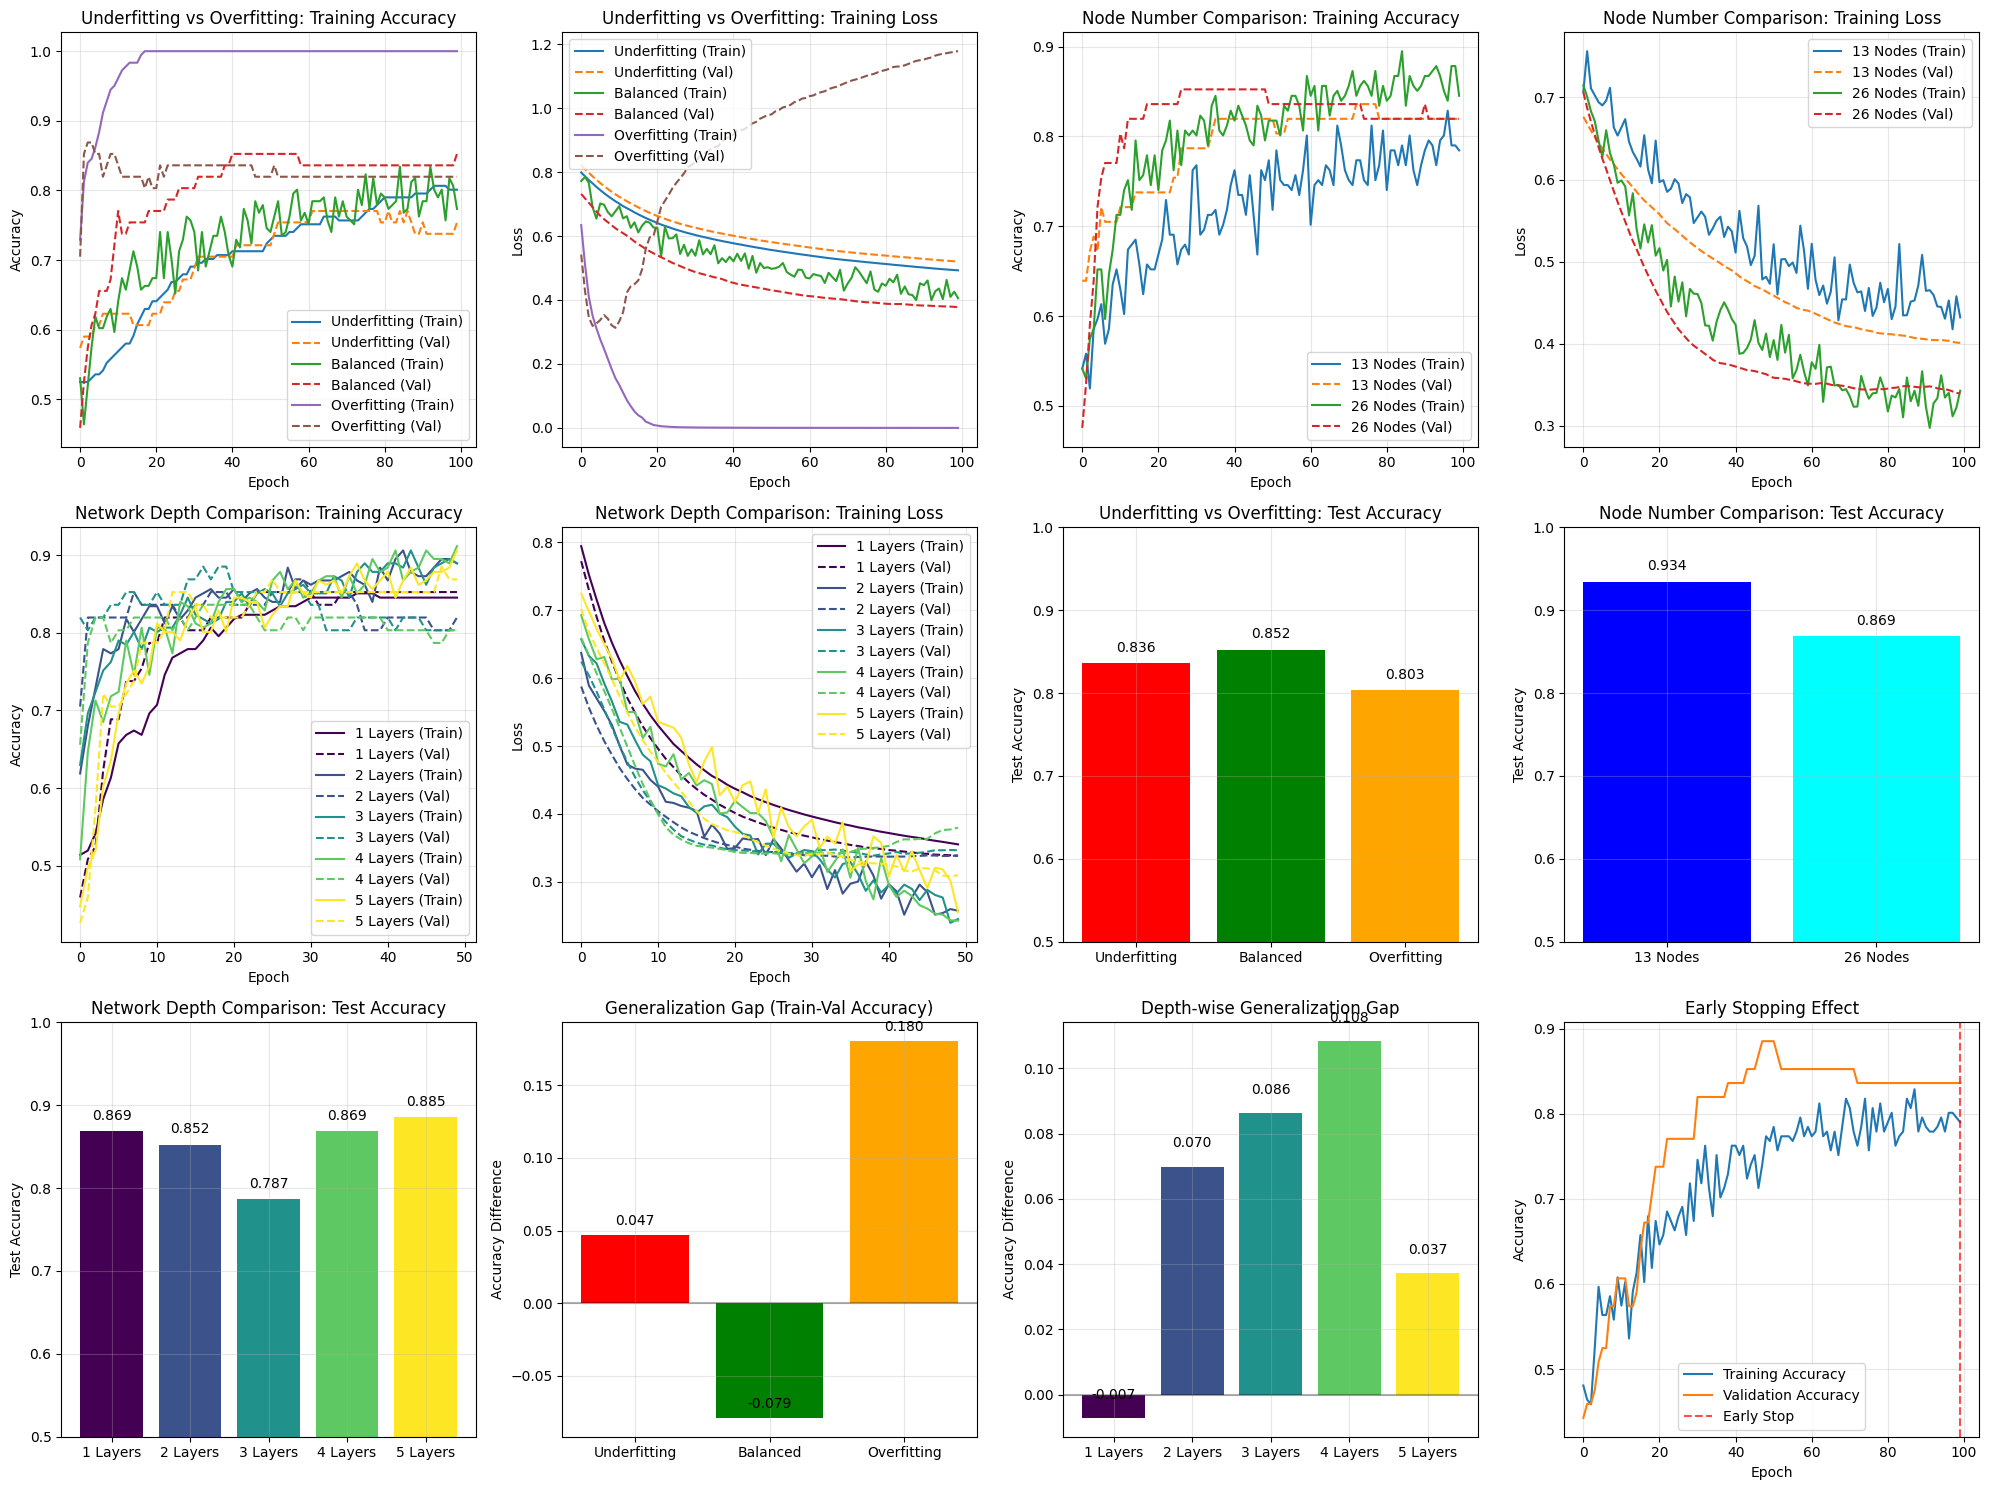


=== Experiment Results Summary ===
1. Underfitting vs Overfitting:
   Underfitting: Test Accuracy 0.8361
   Balanced: Test Accuracy 0.8525
   Overfitting: Test Accuracy 0.8033

2. Node Number Comparison (n=13):
   13 Nodes: Test Accuracy 0.9344
   26 Nodes: Test Accuracy 0.8689

3. Network Depth Comparison (26 nodes):
   1 Layers: Test Accuracy 0.8689
   2 Layers: Test Accuracy 0.8525
   3 Layers: Test Accuracy 0.7869
   4 Layers: Test Accuracy 0.8689
   5 Layers: Test Accuracy 0.8852

4. Final Model (Early Stopping): Test Accuracy 0.8361


In [12]:
# 8. 실험결과 시각화: Visualization

plt.style.use('default')
fig = plt.figure(figsize=(20, 15))

# 8-1. Underfitting vs Overfitting Learning Curves
ax1 = plt.subplot(3, 4, 1)
for name, data in models_comparison.items():
    plt.plot(data['history'].history['accuracy'], label=f'{name} (Train)')
    plt.plot(data['history'].history['val_accuracy'], '--', label=f'{name} (Val)')
plt.title('Underfitting vs Overfitting: Training Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)

ax2 = plt.subplot(3, 4, 2)
for name, data in models_comparison.items():
    plt.plot(data['history'].history['loss'], label=f'{name} (Train)')
    plt.plot(data['history'].history['val_loss'], '--', label=f'{name} (Val)')
plt.title('Underfitting vs Overfitting: Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

# 8-2. Node Number Comparison Learning Curves
ax3 = plt.subplot(3, 4, 3)
for name, data in node_comparison.items():
    plt.plot(data['history'].history['accuracy'], label=f'{name} (Train)')
    plt.plot(data['history'].history['val_accuracy'], '--', label=f'{name} (Val)')
plt.title('Node Number Comparison: Training Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)

ax4 = plt.subplot(3, 4, 4)
for name, data in node_comparison.items():
    plt.plot(data['history'].history['loss'], label=f'{name} (Train)')
    plt.plot(data['history'].history['val_loss'], '--', label=f'{name} (Val)')
plt.title('Node Number Comparison: Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

# 8-3. Depth Comparison Learning Curves
ax5 = plt.subplot(3, 4, 5)
colors = plt.cm.viridis(np.linspace(0, 1, len(depths)))
for i, (name, data) in enumerate(depth_comparison.items()):
    plt.plot(data['history'].history['accuracy'], color=colors[i], label=f'{name} (Train)')
    plt.plot(data['history'].history['val_accuracy'], '--', color=colors[i], label=f'{name} (Val)')
plt.title('Network Depth Comparison: Training Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)

ax6 = plt.subplot(3, 4, 6)
for i, (name, data) in enumerate(depth_comparison.items()):
    plt.plot(data['history'].history['loss'], color=colors[i], label=f'{name} (Train)')
    plt.plot(data['history'].history['val_loss'], '--', color=colors[i], label=f'{name} (Val)')
plt.title('Network Depth Comparison: Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

# 8-4. Test Performance Comparison Bar Charts
ax7 = plt.subplot(3, 4, 7)
model_names = list(models_comparison.keys())
accuracies = [models_comparison[name]['accuracy'] for name in model_names]
bars = plt.bar(model_names, accuracies, color=['red', 'green', 'orange'])
plt.title('Underfitting vs Overfitting: Test Accuracy')
plt.ylabel('Test Accuracy')
plt.ylim(0.5, 1.0)
for bar, acc in zip(bars, accuracies):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
             f'{acc:.3f}', ha='center', va='bottom')
plt.grid(True, alpha=0.3)

ax8 = plt.subplot(3, 4, 8)
node_names = list(node_comparison.keys())
node_accs = [node_comparison[name]['accuracy'] for name in node_names]
bars = plt.bar(node_names, node_accs, color=['blue', 'cyan'])
plt.title('Node Number Comparison: Test Accuracy')
plt.ylabel('Test Accuracy')
plt.ylim(0.5, 1.0)
for bar, acc in zip(bars, node_accs):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
             f'{acc:.3f}', ha='center', va='bottom')
plt.grid(True, alpha=0.3)

ax9 = plt.subplot(3, 4, 9)
depth_names = list(depth_comparison.keys())
depth_accs = [depth_comparison[name]['accuracy'] for name in depth_names]
bars = plt.bar(depth_names, depth_accs, color=colors)
plt.title('Network Depth Comparison: Test Accuracy')
plt.ylabel('Test Accuracy')
plt.ylim(0.5, 1.0)
for bar, acc in zip(bars, depth_accs):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
             f'{acc:.3f}', ha='center', va='bottom')
plt.grid(True, alpha=0.3)

# 8-5. Generalization Performance Analysis (Train vs Validation Accuracy Gap)
ax10 = plt.subplot(3, 4, 10)
generalization_gap = []
model_labels = []

for name, data in models_comparison.items():
    final_train_acc = data['history'].history['accuracy'][-1]
    final_val_acc = data['history'].history['val_accuracy'][-1]
    gap = final_train_acc - final_val_acc
    generalization_gap.append(gap)
    model_labels.append(name)

bars = plt.bar(model_labels, generalization_gap, color=['red', 'green', 'orange'])
plt.title('Generalization Gap (Train-Val Accuracy)')
plt.ylabel('Accuracy Difference')
plt.axhline(y=0, color='black', linestyle='-', alpha=0.3)
for bar, gap in zip(bars, generalization_gap):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
             f'{gap:.3f}', ha='center', va='bottom')
plt.grid(True, alpha=0.3)

# 8-6. Depth-wise Generalization Performance
ax11 = plt.subplot(3, 4, 11)
depth_gen_gap = []
for name, data in depth_comparison.items():
    final_train_acc = data['history'].history['accuracy'][-1]
    final_val_acc = data['history'].history['val_accuracy'][-1]
    gap = final_train_acc - final_val_acc
    depth_gen_gap.append(gap)

bars = plt.bar(depth_names, depth_gen_gap, color=colors)
plt.title('Depth-wise Generalization Gap')
plt.ylabel('Accuracy Difference')
plt.axhline(y=0, color='black', linestyle='-', alpha=0.3)
for bar, gap in zip(bars, depth_gen_gap):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
             f'{gap:.3f}', ha='center', va='bottom')
plt.grid(True, alpha=0.3)

# 8-7. Learning Curve Comparison (Early Stopping Effect)
ax12 = plt.subplot(3, 4, 12)
best_model = create_balanced_model(n_features, n_features)
early_stopping = keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

history_es = best_model.fit(
    X_train_scaled, y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=0
)

plt.plot(history_es.history['accuracy'], label='Training Accuracy')
plt.plot(history_es.history['val_accuracy'], label='Validation Accuracy')
plt.axvline(x=len(history_es.history['accuracy'])-1, color='red', linestyle='--', alpha=0.7, label='Early Stop')
plt.title('Early Stopping Effect')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# 9. Results Summary
print("\n=== Experiment Results Summary ===")
print("1. Underfitting vs Overfitting:")
for name, data in models_comparison.items():
    print(f"   {name}: Test Accuracy {data['accuracy']:.4f}")

print(f"\n2. Node Number Comparison (n={n_features}):")
for name, data in node_comparison.items():
    print(f"   {name}: Test Accuracy {data['accuracy']:.4f}")

print(f"\n3. Network Depth Comparison ({2*n_features} nodes):")
for name, data in depth_comparison.items():
    print(f"   {name}: Test Accuracy {data['accuracy']:.4f}")

print(f"\n4. Final Model (Early Stopping): Test Accuracy {best_model.evaluate(X_test_scaled, y_test, verbose=0)[1]:.4f}")


---
# Task: Bank Marketing 은행 마케팅 예측

**목표:** 은행이 전화를 걸었을 때 **이 고객이 정기예금에 가입할지(yes/no)** 를 ANN 으로 예측하고,
**구조(노드 수·층 깊이)와 학습 설정(EarlyStopping·Dropout)을 바꿔가며 Best Model** 을 찾는다.

**데이터:** Bank Marketing (UCI id=222) — **45,211명 × 16개 변수**
(위 예제 Heart Disease 는 303명 × 13개. **150배 큰 데이터**다.)

> **주의:** 베이스 코드에서 데이터 id 만 바꾸면 에러가 난다.
> Heart Disease 는 전부 숫자인데 Bank Marketing 은 **범주형 변수가 9개**(job, marital, month…)라
> **원핫 인코딩**을 해줘야 `StandardScaler` 가 동작한다.

**진행 순서**
1. 데이터 준비 (전처리 결정)
2. **평가 지표 결정** ← 이 데이터에서 가장 먼저 해야 할 것
3. Over-fitting / Under-fitting 확인
4. Nodes 수 비교
5. Layer Depth 비교
6. EarlyStopping / Dropout 효과
7. Best Model 선정

In [1]:
# ============================================================
# Step 0. 데이터 준비
# ============================================================
import os, time
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, accuracy_score, recall_score,
                             precision_score, confusion_matrix, roc_curve)

bank = fetch_ucirepo(id=222)
Xraw = bank.data.features.copy()
yraw = (bank.data.targets.iloc[:, 0] == "yes").astype(int).values

print(f"원본: {Xraw.shape[0]:,}명 x {Xraw.shape[1]}개 변수")
print(f"타겟: 가입(yes) {yraw.sum():,}명 / 미가입(no) {(1-yraw).sum():,}명"
      f"  ->  가입 비율 {yraw.mean()*100:.2f}%")
print(f"\n** 전부 '미가입' 이라고 찍기만 해도 정확도 {(1-yraw.mean())*100:.2f}% **")
print("   이 숫자를 기억할 것. 뒤에서 계속 발목을 잡는다.")

print("\n=== 결측치 ===")
miss = Xraw.isnull().sum()
print(miss[miss > 0].to_string())
print("   poutcome 은 82% 가 결측 (이전 캠페인이 없었던 고객)")
print("   -> 삭제하지 않고 'missing' 이라는 하나의 범주로 취급한다")

원본: 45,211명 x 16개 변수
타겟: 가입(yes) 5,289명 / 미가입(no) 39,922명  ->  가입 비율 11.70%

** 전부 '미가입' 이라고 찍기만 해도 정확도 88.30% **
   이 숫자를 기억할 것. 뒤에서 계속 발목을 잡는다.

=== 결측치 ===
job            288
education     1857
contact      13020
poutcome     36959
   poutcome 은 82% 가 결측 (이전 캠페인이 없었던 고객)
   -> 삭제하지 않고 'missing' 이라는 하나의 범주로 취급한다


In [2]:
# ============================================================
# Step 0-2. duration 변수를 쓸 것인가?  <- 반드시 짚어야 할 함정
# ============================================================
# UCI 데이터 설명 원문:
#   "this attribute highly affects the output target (e.g., if duration=0 then y='no').
#    Yet, the duration is not known before a call is performed.
#    Thus this input should only be included for benchmark purposes and should be
#    DISCARDED if the intention is to have a realistic predictive model."
#
# duration = '통화 시간'. 통화가 끝나야 알 수 있는 값이다.
# 전화를 걸기 '전에' 가입 여부를 예측하는 게 목적이므로 쓰면 반칙(데이터 누수)이다.

def prep(drop_duration=True):
    X = Xraw.drop(columns=["duration"]) if drop_duration else Xraw.copy()
    for c in X.select_dtypes(exclude=np.number):
        X[c] = X[c].fillna("missing")                          # 결측을 하나의 범주로
    return pd.get_dummies(X, drop_first=True).astype("float32")  # 범주형 -> 원핫

X_all = prep(drop_duration=True)
print(f"원핫 인코딩 후: {Xraw.shape[1]}개 변수 -> {X_all.shape[1]}개 입력")

# Train 60% / Validation 20% / Test 20%  (예제 코드와 같은 방식)
X_tmp, X_te, y_tmp, y_te = train_test_split(X_all, yraw, test_size=0.2,
                                            random_state=42, stratify=yraw)
X_tr, X_va, y_tr, y_va = train_test_split(X_tmp, y_tmp, test_size=0.25,
                                          random_state=42, stratify=y_tmp)
sc = StandardScaler().fit(X_tr)
A, B, T = sc.transform(X_tr), sc.transform(X_va), sc.transform(X_te)
N_IN = A.shape[1]
print(f"Train {A.shape[0]:,} / Validation {B.shape[0]:,} / Test {T.shape[0]:,}   (입력 {N_IN}차원)")
print("\n[역할] Train=학습 / Validation=구조·설정 선택 / Test=맨 마지막 1회만")

원핫 인코딩 후: 16개 변수 -> 41개 입력
Train 27,126 / Validation 9,042 / Test 9,043   (입력 41차원)

[역할] Train=학습 / Validation=구조·설정 선택 / Test=맨 마지막 1회만


---
## Step 1. 평가 지표부터 정한다 ← 이 데이터에서 가장 먼저 할 일

예제 코드(Heart Disease)는 `metrics=['accuracy']` 를 쓴다. Heart Disease 는 클래스가 반반이라 괜찮다.
그런데 **이 데이터는 가입이 11.7% 밖에 안 된다.**

> **아무것도 안 하고 전부 '미가입' 이라고 답해도 정확도 88.3%**

정확도 89% 짜리 모델은 **아무것도 안 한 것보다 겨우 0.7%p 나은 것**일 수도 있다.
정확도로는 모델끼리 구별이 안 된다.

**그래서 AUC 를 쓴다.**
AUC = *"가입할 고객에게 더 높은 점수를 주는가"*. 0.5 면 찍는 것과 같고, 1.0 이면 완벽하다.

In [3]:
# ============================================================
# Step 1. 정확도는 왜 못 쓰는가 -- 숫자로 확인
# ============================================================
rows = [["전부 '미가입' 으로 찍기", 1 - y_te.mean(), 0.5, 0.0]]

lr = LogisticRegression(max_iter=1000).fit(A, y_tr)
p, pr = lr.predict(T), lr.predict_proba(T)[:, 1]
rows.append(["로지스틱 회귀 (duration 제외)", accuracy_score(y_te, p),
             roc_auc_score(y_te, pr), recall_score(y_te, p)])

Xd = prep(drop_duration=False)                       # 반칙 버전 (비교용)
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(Xd, yraw, test_size=0.2,
                                              random_state=42, stratify=yraw)
scd = StandardScaler().fit(Xd_tr)
lrd = LogisticRegression(max_iter=1000).fit(scd.transform(Xd_tr), yd_tr)
pd_ = lrd.predict(scd.transform(Xd_te)); prd = lrd.predict_proba(scd.transform(Xd_te))[:, 1]
rows.append(["로지스틱 회귀 (duration 포함=반칙)", accuracy_score(yd_te, pd_),
             roc_auc_score(yd_te, prd), recall_score(yd_te, pd_)])

R1 = pd.DataFrame(rows, columns=["모델", "정확도", "AUC", "가입자 검출률"])
print(R1.round(4).to_string(index=False))

print("\n[해석] ★ 이번 실습에서 가장 중요한 부분")
print(f"  정확도는 셋 다 0.88~0.90 으로 거의 같다. 최대-최소 차이 {R1['정확도'].max()-R1['정확도'].min():.4f}.")
print(f"  그런데 AUC 는 0.50 -> {R1['AUC'].iloc[1]:.2f} -> {R1['AUC'].iloc[2]:.2f} 로 완전히 갈린다.")
print("  정확도로 비교하면 '아무것도 안 하는 모델' 과도 구별이 안 된다.")
print("\n  또 하나: duration 을 넣으면 AUC 가 확 오른다. 하지만 통화 시간은")
print("  '전화를 걸고 나서' 알 수 있는 값이라 예측에 쓸 수 없다.")
print("  -> 앞으로 모든 실험은 duration 제외 + AUC 평가.")

                      모델    정확도    AUC  가입자 검출률
          전부 '미가입' 으로 찍기 0.8830 0.5000   0.0000
   로지스틱 회귀 (duration 제외) 0.8934 0.7712   0.1767
로지스틱 회귀 (duration 포함=반칙) 0.9014 0.9054   0.3488

[해석] ★ 이번 실습에서 가장 중요한 부분
  정확도는 셋 다 0.88~0.90 으로 거의 같다. 최대-최소 차이 0.0184.
  그런데 AUC 는 0.50 -> 0.77 -> 0.91 로 완전히 갈린다.
  정확도로 비교하면 '아무것도 안 하는 모델' 과도 구별이 안 된다.

  또 하나: duration 을 넣으면 AUC 가 확 오른다. 하지만 통화 시간은
  '전화를 걸고 나서' 알 수 있는 값이라 예측에 쓸 수 없다.
  -> 앞으로 모든 실험은 duration 제외 + AUC 평가.


In [4]:
# ============================================================
# Step 1-2. 실험 도구 -- 모델 생성 / 학습 함수
# ============================================================
# 신경망은 초기 가중치가 랜덤이라 돌릴 때마다 결과가 조금씩 다르다.
# 그래서 모든 실험을 seed 3개로 돌려 평균 +- 표준편차로 본다. (실습2 의 교훈)
SEEDS = [0, 1, 2]

def build(hidden, dropout=0.0):
    m = keras.Sequential([keras.Input(shape=(N_IN,))])
    for h in hidden:
        m.add(layers.Dense(h, activation="relu"))      # 은닉층 ReLU (교재 p.67)
        if dropout > 0:
            m.add(layers.Dropout(dropout))
    m.add(layers.Dense(1, activation="sigmoid"))        # 이진분류 출력층
    m.compile(optimizer="adam", loss="binary_crossentropy",
              metrics=[keras.metrics.AUC(name="auc")])
    return m

def run(hidden, dropout=0.0, epochs=40, early_stop=False, seeds=SEEDS):
    res = {"train": [], "val": [], "test": [], "ep": [], "hist": []}
    for s in seeds:
        keras.utils.set_random_seed(s)
        m = build(hidden, dropout)
        cb = [keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=5,
                                            restore_best_weights=True)] if early_stop else []
        h = m.fit(A, y_tr, validation_data=(B, y_va), epochs=epochs,
                  batch_size=256, verbose=0, callbacks=cb)
        res["train"].append(roc_auc_score(y_tr, m.predict(A, verbose=0).ravel()))
        res["val"].append(roc_auc_score(y_va, m.predict(B, verbose=0).ravel()))
        res["test"].append(roc_auc_score(y_te, m.predict(T, verbose=0).ravel()))
        res["ep"].append(len(h.history["loss"])); res["hist"].append(h.history)
    out = {k: (float(np.mean(v)), float(np.std(v))) for k, v in res.items() if k != "hist"}
    out["hist"] = res["hist"]; out["params"] = m.count_params()
    return out

def row(name, r):
    return {"모델": name, "파라미터수": r["params"],
            "Train AUC": round(r["train"][0], 4), "Val AUC": round(r["val"][0], 4),
            "Val 표준편차": round(r["val"][1], 4),
            "Gap": round(r["train"][0] - r["val"][0], 4)}

t0 = time.time(); _ = run([16], epochs=5, seeds=[0])
print(f"준비 완료 (테스트 학습 {time.time()-t0:.1f}초)")

준비 완료 (테스트 학습 1.1초)


---
## Step 2. Over-fitting / Under-fitting 확인 (공지 항목 1)

실습1 에서 세운 판별 규칙을 그대로 쓴다.

> **Under-fitting** = Gap 작음 **+ Train 성능도 나쁨**
> **Over-fitting** = Gap 큼 **+ Train 은 거의 완벽**
> *"Gap 은 진단 지표이지 최소화 대상이 아니다"*

In [5]:
# ============================================================
# Step 2. 너무 단순 / 적당 / 너무 복잡한 모델
# ============================================================
EXP2 = {"Under (2노드 1층)":       dict(hidden=[2]),
        "Balanced (64-32)":        dict(hidden=[64, 32]),
        "Over (256-128-64-32-16)": dict(hidden=[256, 128, 64, 32, 16])}
res2 = {}
for name, kw in EXP2.items():
    res2[name] = run(epochs=60, **kw); print(f"  {name:26s} 완료")

R2 = pd.DataFrame([row(n, r) for n, r in res2.items()])
R2["진단"] = ["Under-fitting", "균형", "Over-fitting"]
print("\n=== 실험 1 결과 (seed 3개 평균) ===")
print(R2.to_string(index=False))

u, bb, o = R2.iloc[0], R2.iloc[1], R2.iloc[2]
print("\n[해석]")
print(f"  Under : Train {u['Train AUC']} / Val {u['Val AUC']} / Gap {u['Gap']:+.4f}")
print("          Gap 은 작지만 Train 성능 자체가 낮다. 일반화를 잘해서가 아니라")
print("          Train 에서부터 못해서 벌어질 게 없는 것이다. (실습1 결론 그대로)")
print(f"  Over  : Train {o['Train AUC']} / Val {o['Val AUC']} / Gap {o['Gap']:+.4f}")
print(f"          파라미터 {o['파라미터수']:,}개로 Train 을 외웠지만 Val 이 못 따라온다.")
print(f"  Balanced: Val {bb['Val AUC']} 로 가장 높다. 파라미터는 {bb['파라미터수']:,}개뿐.")

  Under (2노드 1층)             완료


  Balanced (64-32)           완료


  Over (256-128-64-32-16)    완료

=== 실험 1 결과 (seed 3개 평균) ===
                     모델  파라미터수  Train AUC  Val AUC  Val 표준편차     Gap            진단
         Under (2노드 1층)     87     0.7693   0.7749    0.0019 -0.0057 Under-fitting
       Balanced (64-32)   4801     0.8822   0.7735    0.0047  0.1087            균형
Over (256-128-64-32-16)  54529     0.9645   0.6842    0.0070  0.2804  Over-fitting

[해석]
  Under : Train 0.7693 / Val 0.7749 / Gap -0.0057
          Gap 은 작지만 Train 성능 자체가 낮다. 일반화를 잘해서가 아니라
          Train 에서부터 못해서 벌어질 게 없는 것이다. (실습1 결론 그대로)
  Over  : Train 0.9645 / Val 0.6842 / Gap +0.2804
          파라미터 54,529개로 Train 을 외웠지만 Val 이 못 따라온다.
  Balanced: Val 0.7735 로 가장 높다. 파라미터는 4,801개뿐.


/var/folders/kv/71cxdxrs3t30w99_t6ytqx3m0000gn/T/ipykernel_15958/2122800035.py:13: UserWarning: Glyph 45432 (\N{HANGUL SYLLABLE NO}) missing from font(s) DejaVu Sans.
  plt.tight_layout(rect=[0, 0, 1, 0.92])
/var/folders/kv/71cxdxrs3t30w99_t6ytqx3m0000gn/T/ipykernel_15958/2122800035.py:13: UserWarning: Glyph 46300 (\N{HANGUL SYLLABLE DEU}) missing from font(s) DejaVu Sans.
  plt.tight_layout(rect=[0, 0, 1, 0.92])
/var/folders/kv/71cxdxrs3t30w99_t6ytqx3m0000gn/T/ipykernel_15958/2122800035.py:13: UserWarning: Glyph 52789 (\N{HANGUL SYLLABLE CEUNG}) missing from font(s) DejaVu Sans.
  plt.tight_layout(rect=[0, 0, 1, 0.92])
/var/folders/kv/71cxdxrs3t30w99_t6ytqx3m0000gn/T/ipykernel_15958/2122800035.py:13: UserWarning: Glyph 47560 (\N{HANGUL SYLLABLE MA}) missing from font(s) DejaVu Sans.
  plt.tight_layout(rect=[0, 0, 1, 0.92])
/var/folders/kv/71cxdxrs3t30w99_t6ytqx3m0000gn/T/ipykernel_15958/2122800035.py:13: UserWarning: Glyph 51648 (\N{HANGUL SYLLABLE JI}) missing from font(s) DejaVu San

/Users/psm/workspace/skala-machine_running/.venv/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 45432 (\N{HANGUL SYLLABLE NO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/psm/workspace/skala-machine_running/.venv/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 46300 (\N{HANGUL SYLLABLE DEU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/psm/workspace/skala-machine_running/.venv/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 52789 (\N{HANGUL SYLLABLE CEUNG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/psm/workspace/skala-machine_running/.venv/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 47560 (\N{HANGUL SYLLABLE MA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/psm/workspace/skala-machine_running/.venv/lib

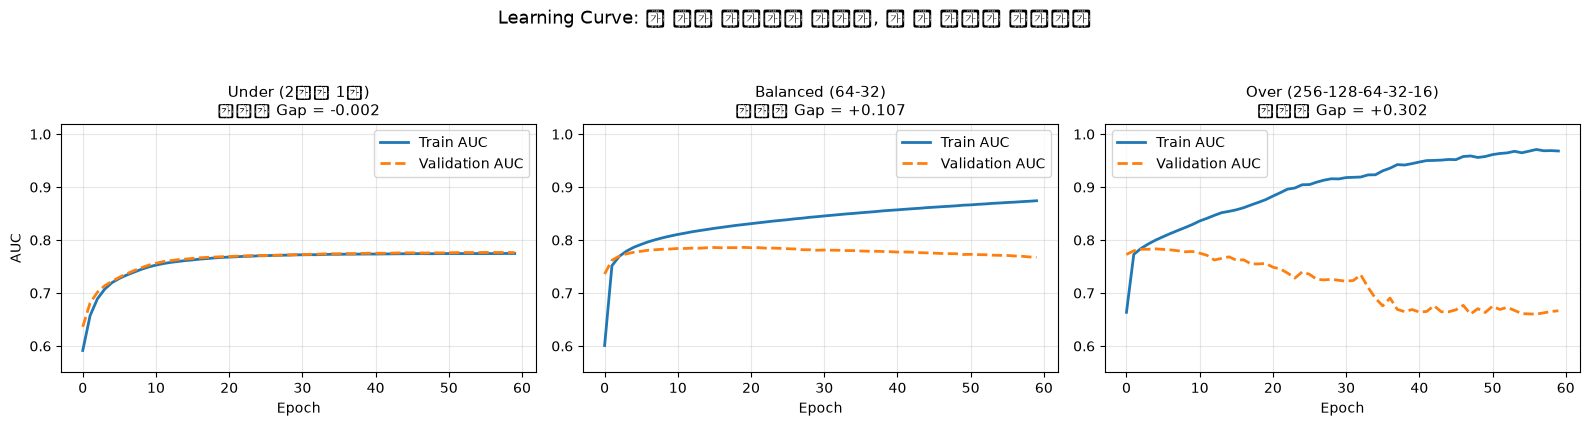

In [6]:
# ============================================================
# [그림 1] Learning Curve -- 과적합이 눈에 보이는 그림
# ============================================================
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
for a, (name, r) in zip(ax, res2.items()):
    h = r["hist"][0]
    a.plot(h["auc"], lw=2, label="Train AUC")
    a.plot(h["val_auc"], lw=2, ls="--", label="Validation AUC")
    a.set_title(f"{name}\n마지막 Gap = {h['auc'][-1]-h['val_auc'][-1]:+.3f}", fontsize=11)
    a.set_xlabel("Epoch"); a.set_ylim(0.55, 1.02); a.grid(alpha=.3); a.legend()
ax[0].set_ylabel("AUC")
fig.suptitle("Learning Curve: 두 선이 벌어지면 과적합, 둘 다 낮으면 과소적합", fontsize=13)
plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.savefig("ann_fig1_fitting.png", dpi=120, bbox_inches="tight"); plt.show()

---
## Step 3. Nodes 수에 따른 성능 (공지 항목 2)

층은 **2층으로 고정**하고 층당 노드 수만 바꾼다 → **용량(capacity)** 손잡이

In [7]:
# ============================================================
# Step 3. 노드 수만 바꾼다 (2층 고정)
# ============================================================
NODES = [4, 8, 16, 32, 64, 128, 256]
res3 = {n: None for n in NODES}
for n in NODES:
    res3[n] = run(hidden=[n, max(n // 2, 4)], epochs=40); print(f"  {n:3d} 노드 완료")

R3 = pd.DataFrame([{"노드수": n, "파라미터수": r["params"],
                    "Train AUC": round(r["train"][0], 4), "Val AUC": round(r["val"][0], 4),
                    "Val 표준편차": round(r["val"][1], 4),
                    "Gap": round(r["train"][0] - r["val"][0], 4)} for n, r in res3.items()])
print("\n=== 실험 2 결과 ==="); print(R3.to_string(index=False))
best_n = int(R3.loc[R3["Val AUC"].idxmax(), "노드수"])
print(f"\n  Val AUC 최고: {best_n}노드 ({R3['Val AUC'].max():.4f})")
print(f"  최고-최저 차이 {R3['Val AUC'].max()-R3['Val AUC'].min():.4f}"
      f"  vs  seed 표준편차 평균 {R3['Val 표준편차'].mean():.4f}")
print(f"  파라미터는 {R3['파라미터수'].min():,} -> {R3['파라미터수'].max():,} 로 늘었는데 성능은?")

    4 노드 완료


    8 노드 완료


   16 노드 완료


   32 노드 완료


   64 노드 완료


  128 노드 완료


  256 노드 완료

=== 실험 2 결과 ===
 노드수  파라미터수  Train AUC  Val AUC  Val 표준편차     Gap
   4    193     0.7692   0.7739    0.0190 -0.0047
   8    377     0.7976   0.7868    0.0015  0.0108
  16    817     0.8095   0.7817    0.0006  0.0277
  32   1889     0.8345   0.7862    0.0032  0.0483
  64   4801     0.8644   0.7818    0.0033  0.0826
 128  13697     0.9053   0.7604    0.0046  0.1449
 256  43777     0.9446   0.7333    0.0044  0.2113

  Val AUC 최고: 8노드 (0.7868)
  최고-최저 차이 0.0535  vs  seed 표준편차 평균 0.0052
  파라미터는 193 -> 43,777 로 늘었는데 성능은?


---
## Step 4. Layer Depth 에 따른 성능 (공지 항목 3)

이번엔 **층당 노드 수를 32로 고정**하고 층 수만 늘린다.

In [8]:
# ============================================================
# Step 4. 층 깊이만 바꾼다 (층당 32노드 고정)
# ============================================================
DEPTHS = [1, 2, 3, 4, 5, 6]
res4 = {}
for d in DEPTHS:
    res4[d] = run(hidden=[32] * d, epochs=40); print(f"  {d}층 완료")

R4 = pd.DataFrame([{"층수": d, "파라미터수": r["params"],
                    "Train AUC": round(r["train"][0], 4), "Val AUC": round(r["val"][0], 4),
                    "Val 표준편차": round(r["val"][1], 4),
                    "Gap": round(r["train"][0] - r["val"][0], 4)} for d, r in res4.items()])
print("\n=== 실험 3 결과 ==="); print(R4.to_string(index=False))
best_d = int(R4.loc[R4["Val AUC"].idxmax(), "층수"])
print(f"\n  Val AUC 최고: {best_d}층 ({R4['Val AUC'].max():.4f})")
print(f"  최고-최저 차이 {R4['Val AUC'].max()-R4['Val AUC'].min():.4f}"
      f"  vs  seed 표준편차 평균 {R4['Val 표준편차'].mean():.4f}")
print("\n[공지 질문] '노드와 층을 늘리면 항상 성능이 좋아지는가?' -> 위 두 표가 답이다.")

  1층 완료


  2층 완료


  3층 완료


  4층 완료


  5층 완료


  6층 완료

=== 실험 3 결과 ===
 층수  파라미터수  Train AUC  Val AUC  Val 표준편차    Gap
  1   1377     0.8205   0.7900    0.0012 0.0305
  2   2433     0.8386   0.7846    0.0014 0.0540
  3   3489     0.8563   0.7726    0.0041 0.0837
  4   4545     0.8661   0.7586    0.0048 0.1075
  5   5601     0.8723   0.7450    0.0123 0.1274
  6   6657     0.8727   0.7369    0.0086 0.1357

  Val AUC 최고: 1층 (0.7900)
  최고-최저 차이 0.0531  vs  seed 표준편차 평균 0.0054

[공지 질문] '노드와 층을 늘리면 항상 성능이 좋아지는가?' -> 위 두 표가 답이다.


/var/folders/kv/71cxdxrs3t30w99_t6ytqx3m0000gn/T/ipykernel_15958/230332027.py:12: UserWarning: Glyph 46160 (\N{HANGUL SYLLABLE DU}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig("ann_fig2_capacity.png", dpi=120, bbox_inches="tight"); plt.show()
/var/folders/kv/71cxdxrs3t30w99_t6ytqx3m0000gn/T/ipykernel_15958/230332027.py:12: UserWarning: Glyph 49440 (\N{HANGUL SYLLABLE SEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig("ann_fig2_capacity.png", dpi=120, bbox_inches="tight"); plt.show()
/var/folders/kv/71cxdxrs3t30w99_t6ytqx3m0000gn/T/ipykernel_15958/230332027.py:12: UserWarning: Glyph 51032 (\N{HANGUL SYLLABLE YI}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig("ann_fig2_capacity.png", dpi=120, bbox_inches="tight"); plt.show()
/var/folders/kv/71cxdxrs3t30w99_t6ytqx3m0000gn/T/ipykernel_15958/230332027.py:12: UserWarning: Glyph 44036 (\N{HANGUL SYLLABLE GAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.save

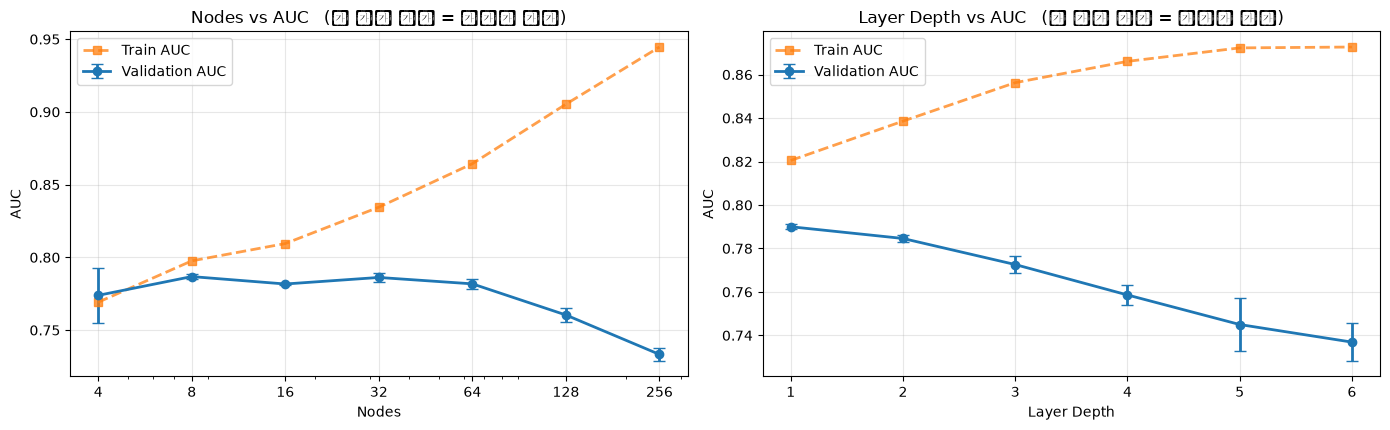

In [9]:
# ============================================================
# [그림 2] 노드 수 / 층 깊이에 따른 성능
# ============================================================
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
for a, (df, xc, ttl) in zip(ax, [(R3, "노드수", "Nodes"), (R4, "층수", "Layer Depth")]):
    a.errorbar(df[xc], df["Val AUC"], yerr=df["Val 표준편차"], fmt="o-", lw=2,
               capsize=4, label="Validation AUC")
    a.plot(df[xc], df["Train AUC"], "s--", lw=2, alpha=.75, label="Train AUC")
    a.set_xlabel(ttl); a.set_ylabel("AUC"); a.grid(alpha=.3); a.legend()
    a.set_title(f"{ttl} vs AUC   (두 선의 간격 = 과적합 정도)")
ax[0].set_xscale("log"); ax[0].set_xticks(NODES); ax[0].set_xticklabels(NODES)
plt.tight_layout(); plt.savefig("ann_fig2_capacity.png", dpi=120, bbox_inches="tight"); plt.show()

---
## Step 5. EarlyStopping / Dropout 효과 (공지 항목 4)

**일부러 과적합하는 큰 모델**(256-128-64-32-16)에 두 기법을 적용해 본다.

| 기법 | 하는 일 | 교재 |
| --- | --- | --- |
| **EarlyStopping** | Validation 이 더 안 좋아지면 학습을 중단 | p.60 |
| **Dropout** | 학습할 때 뉴런을 무작위로 꺼서 골고루 학습 | p.68 |

In [10]:
# ============================================================
# Step 5. 규제 기법 전후 비교 (큰 모델에 적용)
# ============================================================
BIG = [256, 128, 64, 32, 16]
EXP5 = {"규제 없음":               dict(hidden=BIG, dropout=0.0, early_stop=False),
        "EarlyStopping 만":        dict(hidden=BIG, dropout=0.0, early_stop=True),
        "Dropout 0.3 만":          dict(hidden=BIG, dropout=0.3, early_stop=False),
        "EarlyStopping + Dropout": dict(hidden=BIG, dropout=0.3, early_stop=True)}
res5 = {}
for name, kw in EXP5.items():
    res5[name] = run(epochs=60, **kw); print(f"  {name:24s} 완료")

R5 = pd.DataFrame([{"설정": n, "Train AUC": round(r["train"][0], 4),
                    "Val AUC": round(r["val"][0], 4),
                    "Gap": round(r["train"][0] - r["val"][0], 4),
                    "실제 학습 Epoch": round(r["ep"][0], 1)} for n, r in res5.items()])
print("\n=== 실험 4 결과 (큰 모델 기준) ==="); print(R5.to_string(index=False))

base = R5.iloc[0]; best5 = R5.loc[R5["Val AUC"].idxmax()]
print("\n[해석]")
print(f"  규제 없음 : Train {base['Train AUC']} / Val {base['Val AUC']} / Gap {base['Gap']:+.4f}")
print(f"  최고      : {best5['설정']} -> Val {best5['Val AUC']} / Gap {best5['Gap']:+.4f}")
print(f"  Gap 이 {base['Gap']:.4f} -> {R5['Gap'].min():.4f} 로 줄었다 = 외우는 것을 막았다는 뜻.")
print("  EarlyStopping 은 60 epoch 을 다 돌지 않고 알아서 멈춘다(마지막 열).")

  규제 없음                    완료


  EarlyStopping 만          완료


  Dropout 0.3 만            완료


  EarlyStopping + Dropout  완료

=== 실험 4 결과 (큰 모델 기준) ===
                     설정  Train AUC  Val AUC    Gap  실제 학습 Epoch
                  규제 없음     0.9645   0.6842 0.2804         60.0
        EarlyStopping 만     0.8160   0.7863 0.0297          9.7
          Dropout 0.3 만     0.8922   0.7768 0.1153         60.0
EarlyStopping + Dropout     0.8178   0.7942 0.0236         16.7

[해석]
  규제 없음 : Train 0.9645 / Val 0.6842 / Gap +0.2804
  최고      : EarlyStopping + Dropout -> Val 0.7942 / Gap +0.0236
  Gap 이 0.2804 -> 0.0236 로 줄었다 = 외우는 것을 막았다는 뜻.
  EarlyStopping 은 60 epoch 을 다 돌지 않고 알아서 멈춘다(마지막 열).


/var/folders/kv/71cxdxrs3t30w99_t6ytqx3m0000gn/T/ipykernel_15958/2594596993.py:17: UserWarning: Glyph 44508 (\N{HANGUL SYLLABLE GYU}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig("ann_fig3_regular.png", dpi=120, bbox_inches="tight"); plt.show()
/var/folders/kv/71cxdxrs3t30w99_t6ytqx3m0000gn/T/ipykernel_15958/2594596993.py:17: UserWarning: Glyph 51228 (\N{HANGUL SYLLABLE JE}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig("ann_fig3_regular.png", dpi=120, bbox_inches="tight"); plt.show()
/var/folders/kv/71cxdxrs3t30w99_t6ytqx3m0000gn/T/ipykernel_15958/2594596993.py:17: UserWarning: Glyph 44592 (\N{HANGUL SYLLABLE GI}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig("ann_fig3_regular.png", dpi=120, bbox_inches="tight"); plt.show()
/var/folders/kv/71cxdxrs3t30w99_t6ytqx3m0000gn/T/ipykernel_15958/2594596993.py:17: UserWarning: Glyph 48277 (\N{HANGUL SYLLABLE BEOB}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.sav

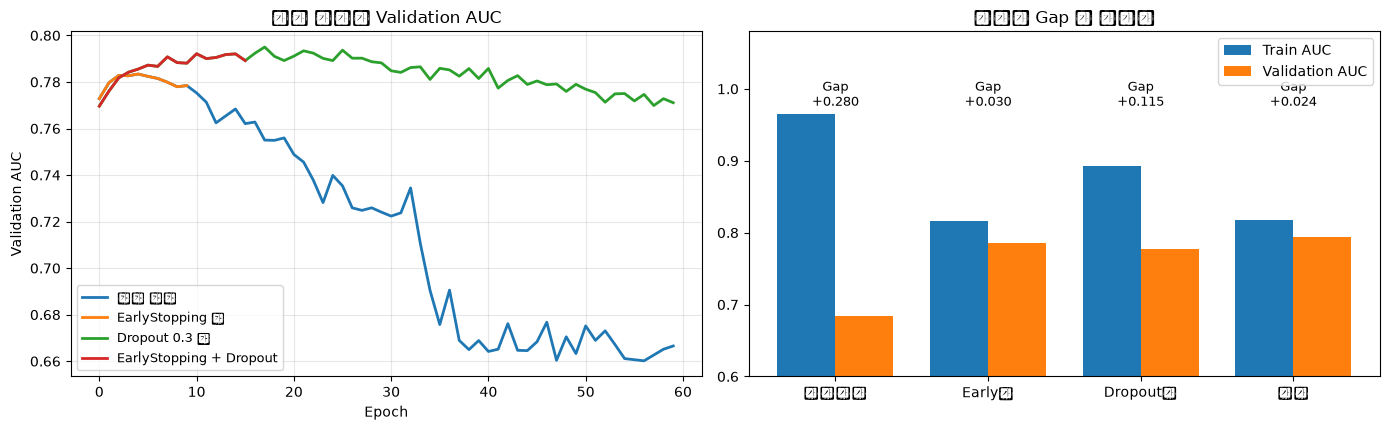

In [11]:
# ============================================================
# [그림 3] 규제 효과
# ============================================================
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
for name, r in res5.items():
    ax[0].plot(r["hist"][0]["val_auc"], lw=2, label=name)
ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Validation AUC")
ax[0].set_title("규제 기법별 Validation AUC"); ax[0].legend(fontsize=9); ax[0].grid(alpha=.3)

x = np.arange(len(R5)); w = 0.38
ax[1].bar(x - w/2, R5["Train AUC"], w, label="Train AUC")
ax[1].bar(x + w/2, R5["Val AUC"], w, label="Validation AUC")
for i, g in enumerate(R5["Gap"]):
    ax[1].text(i, R5["Train AUC"].max() + 0.012, f"Gap\n{g:+.3f}", ha="center", fontsize=9)
ax[1].set_xticks(x); ax[1].set_xticklabels(["규제없음", "Early만", "Dropout만", "둘다"], fontsize=10)
ax[1].set_ylim(0.6, 1.08); ax[1].legend(); ax[1].set_title("규제는 Gap 을 줄인다")
plt.tight_layout(); plt.savefig("ann_fig3_regular.png", dpi=120, bbox_inches="tight"); plt.show()

---
## Step 6. Best Model 선정 (공지 항목 5)

**성능이 비슷하면 무엇으로 고를 것인가?** 실습2·3 과 같이 **규칙을 먼저 정한다.**

| 순서 | 규칙 | 이유 |
| --- | --- | --- |
| ① | **Validation AUC** 기준 (정확도 아님) | 정확도로는 구별이 안 된다 |
| ② | seed 표준편차 안에서 동률이면 **더 단순한 모델** | 큰 차이가 아니면 작은 쪽이 낫다 |
| ③ | 그래도 동률이면 **Gap 이 작은 쪽** | 일반화 여지가 크다 |
| ④ | **Test 는 마지막에 한 번만** | 실습1~3 에서 반복한 원칙 |

In [12]:
# ============================================================
# Step 6. 후보 비교 -> 최종 선정 -> Test 1회
# ============================================================
CAND = {
    f"작은 ({best_n}-{max(best_n//2,4)}) + Early":  dict(hidden=[best_n, max(best_n//2,4)], dropout=0.0, early_stop=True),
    "중간 (64-32) + Early + Dropout":               dict(hidden=[64, 32], dropout=0.3, early_stop=True),
    "큰 모델 + Early + Dropout":                    dict(hidden=BIG, dropout=0.3, early_stop=True),
}
res6 = {n: run(epochs=60, **kw) for n, kw in CAND.items()}
R6 = pd.DataFrame([{"후보": n, "파라미터수": r["params"], "Val AUC": round(r["val"][0], 4),
                    "Val 표준편차": round(r["val"][1], 4),
                    "Gap": round(r["train"][0] - r["val"][0], 4)} for n, r in res6.items()])
print("=== 최종 후보 ==="); print(R6.to_string(index=False))

top = R6["Val AUC"].max(); tol = float(R6.loc[R6["Val AUC"].idxmax(), "Val 표준편차"])
tie = R6[R6["Val AUC"] >= top - tol]
BEST = tie.loc[tie["파라미터수"].idxmin(), "후보"]         # 규칙 ②
print(f"\n최고 Val AUC {top:.4f}, seed 표준편차 {tol:.4f}")
print(f"표준편차 안에 드는 후보 {len(tie)}개 -> 그중 가장 단순한 것 선택")
print(f"\n=> 최종 Best Model: {BEST}")

# --- Test 는 여기서 처음이자 마지막으로 연다 ---
keras.utils.set_random_seed(0)
kwb = CAND[BEST]
final = build(kwb["hidden"], kwb["dropout"])
cbs = [keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=5,
                                     restore_best_weights=True)] if kwb["early_stop"] else []
hf = final.fit(A, y_tr, validation_data=(B, y_va), epochs=60, batch_size=256,
               verbose=0, callbacks=cbs)
prob = final.predict(T, verbose=0).ravel(); pred = (prob >= 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()

print("\n" + "=" * 62); print("  Test 최종 평가 (9,043명)"); print("=" * 62)
print(f"  AUC            {roc_auc_score(y_te, prob):.4f}")
print(f"  정확도          {accuracy_score(y_te, pred):.4f}   (전부 미가입 = {1-y_te.mean():.4f})")
print(f"  가입자 검출률    {recall_score(y_te, pred):.4f}   (실제 가입 {tp+fn:,}명 중 {tp:,}명)")
print(f"  가입 예측 정밀도 {precision_score(y_te, pred, zero_division=0):.4f}")
print(f"\n  혼동행렬   실제 미가입 : 맞춤 {tn:5,} / 헛짚음 {fp:4,}")
print(f"             실제 가입   : 놓침 {fn:5,} / 맞춤   {tp:4,}")
print("\n[주의] 정확도만 보면 '전부 미가입' 과 큰 차이가 없어 보이지만,")
print("       AUC 와 검출률을 보면 모델이 실제로 가입자를 골라내고 있다.")

=== 최종 후보 ===
                          후보  파라미터수  Val AUC  Val 표준편차    Gap
            작은 (8-4) + Early    377   0.7872    0.0018 0.0092
중간 (64-32) + Early + Dropout   4801   0.7972    0.0041 0.0210
      큰 모델 + Early + Dropout  54529   0.7942    0.0014 0.0236

최고 Val AUC 0.7972, seed 표준편차 0.0041
표준편차 안에 드는 후보 2개 -> 그중 가장 단순한 것 선택

=> 최종 Best Model: 중간 (64-32) + Early + Dropout



  Test 최종 평가 (9,043명)
  AUC            0.7913
  정확도          0.8938   (전부 미가입 = 0.8830)
  가입자 검출률    0.1626   (실제 가입 1,058명 중 172명)
  가입 예측 정밀도 0.6992

  혼동행렬   실제 미가입 : 맞춤 7,911 / 헛짚음   74
             실제 가입   : 놓침   886 / 맞춤    172

[주의] 정확도만 보면 '전부 미가입' 과 큰 차이가 없어 보이지만,
       AUC 와 검출률을 보면 모델이 실제로 가입자를 골라내고 있다.


/var/folders/kv/71cxdxrs3t30w99_t6ytqx3m0000gn/T/ipykernel_15958/2570062781.py:25: UserWarning: Glyph 52572 (\N{HANGUL SYLLABLE COE}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig("ann_fig4_final.png", dpi=120, bbox_inches="tight"); plt.show()
/var/folders/kv/71cxdxrs3t30w99_t6ytqx3m0000gn/T/ipykernel_15958/2570062781.py:25: UserWarning: Glyph 51333 (\N{HANGUL SYLLABLE JONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig("ann_fig4_final.png", dpi=120, bbox_inches="tight"); plt.show()
/var/folders/kv/71cxdxrs3t30w99_t6ytqx3m0000gn/T/ipykernel_15958/2570062781.py:25: UserWarning: Glyph 47784 (\N{HANGUL SYLLABLE MO}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig("ann_fig4_final.png", dpi=120, bbox_inches="tight"); plt.show()
/var/folders/kv/71cxdxrs3t30w99_t6ytqx3m0000gn/T/ipykernel_15958/2570062781.py:25: UserWarning: Glyph 45944 (\N{HANGUL SYLLABLE DEL}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(

/Users/psm/workspace/skala-machine_running/.venv/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 52237 (\N{HANGUL SYLLABLE JJIG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/psm/workspace/skala-machine_running/.venv/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 44592 (\N{HANGUL SYLLABLE GI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/psm/workspace/skala-machine_running/.venv/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 51076 (\N{HANGUL SYLLABLE IM}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/psm/workspace/skala-machine_running/.venv/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 44228 (\N{HANGUL SYLLABLE GYE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/psm/workspace/skala-machine_running/.venv/lib/

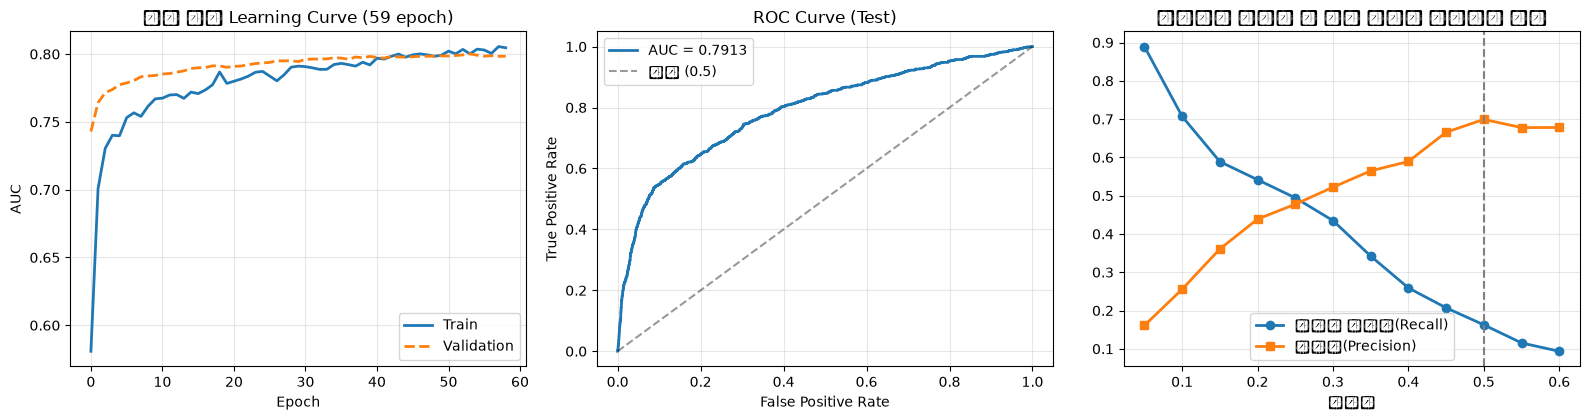

In [13]:
# ============================================================
# [그림 4] 최종 모델 -- Learning Curve / ROC / 임계값
# ============================================================
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
ax[0].plot(hf.history["auc"], lw=2, label="Train")
ax[0].plot(hf.history["val_auc"], lw=2, ls="--", label="Validation")
ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("AUC"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[0].set_title(f"최종 모델 Learning Curve ({len(hf.history['loss'])} epoch)")

fpr, tpr, _ = roc_curve(y_te, prob)
ax[1].plot(fpr, tpr, lw=2, label=f"AUC = {roc_auc_score(y_te, prob):.4f}")
ax[1].plot([0, 1], [0, 1], "k--", alpha=.4, label="찍기 (0.5)")
ax[1].set_xlabel("False Positive Rate"); ax[1].set_ylabel("True Positive Rate")
ax[1].set_title("ROC Curve (Test)"); ax[1].legend(); ax[1].grid(alpha=.3)

ths = np.arange(0.05, 0.65, 0.05); rec, pre = [], []
for t_ in ths:
    q = (prob >= t_).astype(int)
    rec.append(recall_score(y_te, q)); pre.append(precision_score(y_te, q, zero_division=0))
ax[2].plot(ths, rec, "o-", lw=2, label="가입자 검출률(Recall)")
ax[2].plot(ths, pre, "s-", lw=2, label="정밀도(Precision)")
ax[2].axvline(0.5, ls="--", c="gray"); ax[2].set_xlabel("임계값")
ax[2].set_title("임계값을 낮추면 더 많이 잡지만 헛수고도 는다")
ax[2].legend(); ax[2].grid(alpha=.3)
plt.tight_layout(); plt.savefig("ann_fig4_final.png", dpi=120, bbox_inches="tight"); plt.show()

---
## 결론

In [14]:
# ============================================================
#  최종 요약 -- 이 셀 하나로 결과 전체 확인
# ============================================================
print("=" * 68); print("  BEST MODEL"); print("=" * 68)
kwb = CAND[BEST]
print(f"""
  구조         : 입력 {N_IN} -> {' -> '.join(str(h) for h in kwb['hidden'])} -> 1
  활성화 함수   : 은닉층 ReLU / 출력층 Sigmoid
  Optimizer    : Adam,   Loss: binary_crossentropy
  Dropout      : {kwb['dropout']}
  EarlyStopping: {'적용 (patience=5)' if kwb['early_stop'] else '미적용'}
  Batch Size   : 256
  전처리        : duration 제외(누수) + 원핫 인코딩 + 표준화
""")
print(f"  Train AUC {res6[BEST]['train'][0]:.4f} | Val AUC {res6[BEST]['val'][0]:.4f}"
      f" | Test AUC {roc_auc_score(y_te, prob):.4f}")
print(f"  Test 정확도 {accuracy_score(y_te, pred):.4f}   (전부 미가입 = {1-y_te.mean():.4f})")

print("\n" + "=" * 68); print("  실험 요약"); print("=" * 68)
print("\n[1] 과소적합 vs 과대적합"); print(R2[["모델","파라미터수","Train AUC","Val AUC","Gap","진단"]].to_string(index=False))
print("\n[2] 노드 수");            print(R3.to_string(index=False))
print("\n[3] 층 깊이");            print(R4.to_string(index=False))
print("\n[4] 규제 기법");          print(R5.to_string(index=False))

print("\n" + "=" * 68); print("  이번 실습에서 배운 것"); print("=" * 68)
print(f"""
  1) 지표를 먼저 정해야 한다
     가입이 11.7% 뿐이라 '전부 미가입' 으로 찍어도 정확도 {1-y_te.mean():.1%} 다.
     정확도로는 모델끼리 구별이 안 되어 AUC 를 썼다.

  2) 노드와 층을 늘려도 성능은 좋아지지 않았다
     노드 {NODES[0]}->{NODES[-1]}: Val AUC 차이 {R3['Val AUC'].max()-R3['Val AUC'].min():.4f}
     층   {DEPTHS[0]}->{DEPTHS[-1]}: Val AUC 차이 {R4['Val AUC'].max()-R4['Val AUC'].min():.4f}
     파라미터는 {R3['파라미터수'].min():,} -> {R3['파라미터수'].max():,} 로 늘었는데도 그렇다.
     대신 Gap 은 계속 커졌다 = 늘어난 용량이 '외우는 데' 쓰였다.

  3) EarlyStopping / Dropout 은 Gap 을 줄였다
     규제 없음 Gap {R5.iloc[0]['Gap']:+.4f} -> 규제 적용 {R5['Gap'].min():+.4f}

  4) duration 을 쓰면 AUC 가 {R1['AUC'].iloc[1]:.2f} -> {R1['AUC'].iloc[2]:.2f} 로 뛴다
     하지만 통화 시간은 전화를 걸고 나서야 알 수 있어 예측에 쓸 수 없다.
     '성능이 갑자기 좋아지면 누수를 의심해야 한다.'
""")
print("=" * 68)

  BEST MODEL

  구조         : 입력 41 -> 64 -> 32 -> 1
  활성화 함수   : 은닉층 ReLU / 출력층 Sigmoid
  Optimizer    : Adam,   Loss: binary_crossentropy
  Dropout      : 0.3
  EarlyStopping: 적용 (patience=5)
  Batch Size   : 256
  전처리        : duration 제외(누수) + 원핫 인코딩 + 표준화

  Train AUC 0.8182 | Val AUC 0.7972 | Test AUC 0.7913
  Test 정확도 0.8938   (전부 미가입 = 0.8830)

  실험 요약

[1] 과소적합 vs 과대적합
                     모델  파라미터수  Train AUC  Val AUC     Gap            진단
         Under (2노드 1층)     87     0.7693   0.7749 -0.0057 Under-fitting
       Balanced (64-32)   4801     0.8822   0.7735  0.1087            균형
Over (256-128-64-32-16)  54529     0.9645   0.6842  0.2804  Over-fitting

[2] 노드 수
 노드수  파라미터수  Train AUC  Val AUC  Val 표준편차     Gap
   4    193     0.7692   0.7739    0.0190 -0.0047
   8    377     0.7976   0.7868    0.0015  0.0108
  16    817     0.8095   0.7817    0.0006  0.0277
  32   1889     0.8345   0.7862    0.0032  0.0483
  64   4801     0.8644   0.7818    0.0033  0.0826
 128  13697     0.